# Machine learning -- Jour 1
## Numpy Pandas: Manipuler et nettoyer des donnees

## 0. Mise en place
Avant de lancer la moindre cellule:
1. Recuperer le fichier 'notes_etudiants.csv' fourni par l'enseignant
2. Placez-le **dans le meme dossier** qu ce notebook.
3. Si une cellule plus bas renvoie une erruer 'FileNotFoundError', c'est que le fichier n'est pas au bon endroit -- deplacez-le, ou remplacez '"notes_etudiants.csv"' par son chemin complet (ex. /home/rwan-alex/Machine Learning sous linux)

In [17]:
# Verification rapide : le fichier est-il accessible depuis ce dossier?
import os
if os.path.exists("notes_etudiants.csv"):
   print("fichier trouve")
else:
   print("Fichier introuvable : verifiez son emplacement")

fichier trouve


In [18]:
#Apercu rapide du fichier brut
with open("notes_etudiants.csv", encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().strip())

id,nom,filiere,note_maths,note_info,note_physique,ville
1,Sophie Ngono,RT,11.07,13.92,15.91,Bertoua
2,Léa Ngono,GI,14.95,14.12,,Bertoua
3,David Tchoumi,GC,7.18,13.85,8.4,Ngaoundéré
4,Léa Kamga,RT,18.94,16.92,19.36,Bafoussam


## 2. Premiere tentative: Python pur
Sans bibliotheque, on doit tout faire "a la main": ouverture du fichier, parsing ligne par ligne, gestions manuelle des erreurs, boucles imbriques pour les agregations 

In [21]:
import csv
import time

start= time.time()

total=0
count=0

with open("notes_etudiants.csv", encoding="utf-8") as f:
    reader= csv.DictReader(f)
    for _ in range (5):
        print(reader)
    for rov in reader:
        try:
            note=float(rov["note_maths"])
            total += note
            count+=1
        except ValueError:
            pass #note manquante ou invalide

moyenne=total /count
elapsed= time.time() - start

print(f"Moyenne generale en maths : {moyenne:.2f}")
print(f"Temps d'execution : {elapsed*100:.2f}ms")




Moyenne generale en maths : 10.99
Temps d'execution : 4.79ms


** A retenir **: Ce code fonctionne, mais il devient vite illisble des qu

## 3. Numpy: le calcul vectorise

Numpy remplace les boucles Python par des operations vectorisees, executees en code C en interne.
Un tableau Numpy ("ndarray") est homogene et permet d'appliquer une operation a toutes les valeurs en une seule instruction

In [ ]:
import numpy as np
notes= np.array([12.5,8.0, 15.25, 9.75, 18.0])

print("Moyenne :", notes.mean())
print("Ecart-type :", notes.std())
print("Notes  > 12:", notes[notes>12])
print("Nb > 12:", (notes >12).sum()) #Pour compter le nombre d'utilisateurs

Moyenne : 12.7
Ecart-type : 3.6173194495371845
Notes  > 12: [12.5  15.25 18.  ]
Nb > 12: 3


** Concepts cles a experimenter **:
- Creation: 'np.array', 'np.zeros', 'np.arrange', 'np.linspace'
- Indexation booleenne (masques)
- Operationds element par element (broadcasting)
- Fonctions d'agregation: 'mean', 'sum', 'std', 'min', 'max'

In [23]:
# Exemple : broadcasting
notes_sur_20= np.array([8,12,15,19,6])
notes_sur_100= notes_sur_20* 5  #operation appliquee a tout le tableau, sans boucle
print(notes_sur_100)

[40 60 75 95 30]


In [25]:
import pandas as pd
import time

start =time.time()

df=pd.read_csv("notes_etudiants.csv")

print(df.head)
print()
print("Moyenne generale en maths :", (df["note_maths"]).mean())
print("Nb etudiants > 12 :",(df["note_maths"]>12).sum())

elapsed= time.time() - start
print(f"\n Temps d'execution : {elapsed*1000:.2f} ms")

<bound method NDFrame.head of         id            nom filiere  note_maths  note_info  note_physique  \
0        1   Sophie Ngono      RT       11.07      13.92          15.91   
1        2      Léa Ngono      GI       14.95      14.12            NaN   
2        3  David Tchoumi      GC        7.18      13.85           8.40   
3        4      Léa Kamga      RT       18.94      16.92          19.36   
4        5  Cédric Mbarga      RT       14.13       8.10          12.56   
...    ...            ...     ...         ...        ...            ...   
4995  4996     Carine Eto      GI       10.53      10.08           4.75   
4996  4997      Léa Sango      TI       15.78       8.02          10.68   
4997  4998    Aline Kamga     EII       10.59      14.02          14.41   
4998  4999    Steve Mfomo      TI       13.16      19.50          13.06   
4999  5000  Carine Mvondo      RT       14.41      10.55           0.89   

           ville  
0        Bertoua  
1        Bertoua  
2     Ngaoun

In [27]:
#Moyenne par filiere, triee par ordre decroissant
df.groupby("filiere")["note_info"].mean().sort_values(ascending=False)

filiere
TI     12.138691
GI     12.078291
EII    11.971256
GC     11.941764
RT     11.857386
Name: note_info, dtype: float64

In [28]:
# Combien de valeurs manquantes par colonne?
df.isna().sum()

id                 0
nom                0
filiere            0
note_maths         0
note_info          0
note_physique    167
ville              0
dtype: int64

In [29]:
# Option 1: remplacer par la moyenne
df["note_physique"]=df["note_physique"].fillna(df["note_physique"].mean())

#Option 2 (alternative) : supprimer les lignes incompletes
#df=df.dropna(subset=["note_physique"])

df.isna().sum() #verification : plus de valeurs manquantes

id               0
nom              0
filiere          0
note_maths       0
note_info        0
note_physique    0
ville            0
dtype: int64

In [8]:
import pandas as pd
df=pd.read_csv("notes_etudiants.csv")
print(df.describe())
print("That's great")
df.info()

                id   note_maths    note_info  note_physique
count  5000.000000  5000.000000  5000.000000    4833.000000
mean   2500.500000    10.985032    11.996466       9.916058
std    1443.520003     3.997952     3.459939       4.417684
min       1.000000     0.000000     0.000000       0.000000
25%    1250.750000     8.270000     9.660000       6.920000
50%    2500.500000    10.990000    12.030000      10.000000
75%    3750.250000    13.750000    14.320000      12.940000
max    5000.000000    20.000000    20.000000      20.000000
That's great
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             5000 non-null   int64  
 1   nom            5000 non-null   str    
 2   filiere        5000 non-null   str    
 3   note_maths     5000 non-null   float64
 4   note_info      5000 non-null   float64
 5   note_physique  4833 non-null   float64


/tmp/ipykernel_6922/2000087589.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df=pd.read_csv("notes_etudiants.csv", index_col=0, parse_dates=True)


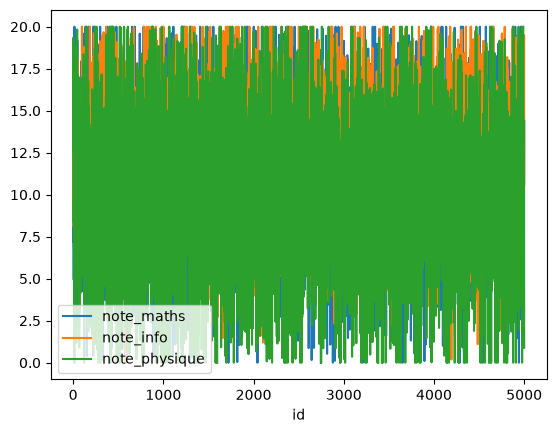

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv("notes_etudiants.csv", index_col=0, parse_dates=True)
df.plot()

plt.show()



In [35]:
import pandas as pd
df=pd.read_csv("notes_etudiants.csv")
df.groupby("filiere")[["note_info","note_maths","ville"]].mean(numeric_only=True)

,note_info,note_maths
filiere,,
EII,11.971256,11.086156
GC,11.941764,11.030591
GI,12.078291,10.951132
RT,11.857386,10.847457
TI,12.138691,11.000745


In [36]:
import pandas as pd
df=pd.read_csv("notes_etudiants.csv")

d=df[df["note_info"]==10]
final= d[["ville","id"]]
print(final)
# df.loc[df["note_info"]==10, ["ville", "id"]]

           ville    id
1071      Garoua  1072
1915      Douala  1916
3141      Douala  3142
3190      Douala  3191
3870     Yaoundé  3871
4077     Bertoua  4078
4457  Ngaoundéré  4458


In [43]:
import pandas as pd
df=pd.read_csv("notes_etudiants.csv")

#df[["note_maths","note_info"]].median()

df.sort_values(by=["filiere","ville"],ascending=False)

,id,nom,filiere,note_maths,note_info,note_physique,ville
20,21,Carine Ngono,TI,17.98,6.12,14.46,Yaoundé
64,65,Stéphanie Eto,TI,14.66,16.27,16.98,Yaoundé
79,80,Jean Atangana,TI,5.54,12.29,15.08,Yaoundé
105,106,Pauline Talla,TI,6.84,17.50,5.42,Yaoundé
151,152,Junior Mbarga,TI,14.13,9.03,5.28,Yaoundé
...,...,...,...,...,...,...,...
4909,4910,Steve Mbarga,EII,15.25,19.37,9.51,Bafoussam
4919,4920,Brenda Eto,EII,1.46,15.57,7.61,Bafoussam
4935,4936,Patrick Talla,EII,15.09,5.62,3.34,Bafoussam
4980,4981,Hervé Biya,EII,10.66,8.86,4.86,Bafoussam
